In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Load dataset
df = pd.read_csv(
    "../datasets/raw/graduate_admissions/Admission_Predict.csv"
)

# Clean column names
df.columns = df.columns.str.strip()

# Remove unnecessary ID column
df = df.drop(columns=["Serial No."])

# Separate features and target
X = df.drop(columns=["Chance of Admit"])
y = df["Chance of Admit"]

# Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Standardize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert target to NumPy arrays
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (320, 7)
Testing features: (80, 7)
Training target: (320,)
Testing target: (80,)


In [4]:
# Number of input features
n_features = X_train.shape[1]

# Initialize weights and bias
weights = np.zeros(n_features)
bias = 0.0

print("Initial weights:", weights)
print("Initial bias:", bias)

Initial weights: [0. 0. 0. 0. 0. 0. 0.]
Initial bias: 0.0


In [5]:
def predict(X, weights, bias):
    return np.dot(X, weights) + bias

In [6]:
predictions = predict(X_train, weights, bias)

print("First 5 predictions:", predictions[:5])
print("First 5 actual values:", y_train[:5])

First 5 predictions: [0. 0. 0. 0. 0.]
First 5 actual values: [0.8  0.63 0.97 0.74 0.58]


In [7]:
# cost function
def calculate_mse(y_actual, y_predicted):
    return np.mean((y_actual - y_predicted) ** 2)

In [8]:
initial_mse = calculate_mse(
    y_train,
    predictions
)

print("Initial Training MSE:", initial_mse)

Initial Training MSE: 0.5449309375


In [9]:
def calculate_gradients(X, y, predictions):
    n = len(y)

    error = predictions - y

    dw = (2 / n) * np.dot(X.T, error)
    db = (2 / n) * np.sum(error)

    return dw, db

In [10]:
def gradient_descent(X, y, learning_rate=0.05, epochs=5000):

    n_features = X.shape[1]

    # Initialize parameters
    weights = np.zeros(n_features)
    bias = 0.0

    mse_history = []

    for epoch in range(epochs):

        # Step 1: Make predictions
        predictions = predict(X, weights, bias)

        # Step 2: Calculate error
        mse = calculate_mse(y, predictions)

        # Store MSE
        mse_history.append(mse)

        # Step 3: Calculate gradients
        dw, db = calculate_gradients(X, y, predictions)

        # Step 4: Update weights and bias
        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

    return weights, bias, mse_history

In [11]:
# training


weights, bias, mse_history = gradient_descent(
    X_train,
    y_train,
    learning_rate=0.05,
    epochs=5000
)

print("Training completed!")

print("\nLearned weights:")
print(weights)

print("\nLearned bias:")
print(bias)

print("\nFinal Training MSE:")
print(mse_history[-1])

Training completed!

Learned weights:
[ 0.02099652  0.01639522  0.00844812 -0.00029857  0.01413835  0.0673812
  0.01108222]

Learned bias:
0.7252812499999995

Final Training MSE:
0.0038704218434173236


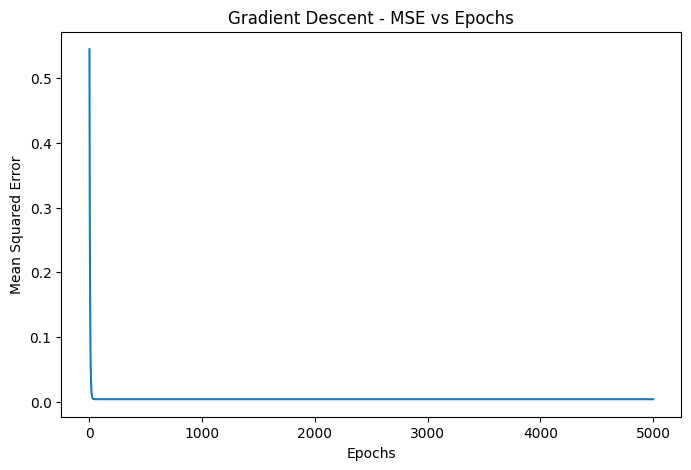

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(mse_history)

plt.title("Gradient Descent - MSE vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.show()

In [13]:
y_pred = predict(X_test, weights, bias)

print("First 10 actual values:")
print(y_test[:10])

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[0.68 0.68 0.9  0.79 0.44 0.94 0.43 0.36 0.72 0.85]

First 10 predicted values:
[0.65117446 0.72368741 0.93536809 0.82164316 0.58158673 0.92863016
 0.52682366 0.54308993 0.65940583 0.83834924]


In [14]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Linear Regression - Gradient Descent")
print("-------------------------------------")
print("MSE :", round(mse, 5))
print("RMSE:", round(rmse, 5))
print("R²  :", round(r2, 5))

Linear Regression - Gradient Descent
-------------------------------------
MSE : 0.00462
RMSE: 0.06795
R²  : 0.82121


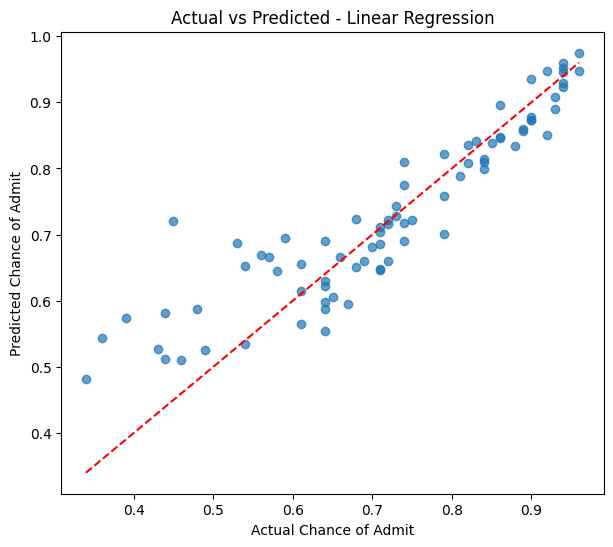

In [15]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Chance of Admit")
plt.ylabel("Predicted Chance of Admit")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

In [16]:
y_train_pred = predict(X_train, weights, bias)

train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

print("Training Performance")
print("--------------------")
print("MSE :", round(train_mse, 5))
print("RMSE:", round(train_rmse, 5))
print("R²  :", round(train_r2, 5))

Training Performance
--------------------
MSE : 0.00387
RMSE: 0.06221
R²  : 0.79519


In [17]:
y_train_pred = predict(X_train, weights, bias)

train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

print("Training MSE:", round(train_mse, 5))
print("Training RMSE:", round(train_rmse, 5))
print("Training R2:", round(train_r2, 5))

Training MSE: 0.00387
Training RMSE: 0.06221
Training R2: 0.79519
